<a href="https://colab.research.google.com/github/priskach/PCD_TI_FSaintek/blob/main/M06%20-%20Contrast%20Enhance%20%26%20Gray%20Level%20Slice/Praktikum%206%20Operasi_Piksel_Histogram_Kontras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 6 — Operasi Piksel, Histogram, & Peningkatan Kontras


## Tujuan Pembelajaran
Setelah mengikuti praktikum ini, mahasiswa mampu:
1. Memahami konsep piksel dan intensitas citra.
2. Melakukan manipulasi nilai piksel.
3. Mengatur brightness dan contrast.
4. Membuat dan menganalisis histogram citra.


## Petunjuk Penggunaan Praktikum ini

Ikuti notebook **secara berurutan**. Pada bagian yang diberi label **Praktikum**, jangan hanya menjalankan kode.

Lakukan 3 hal:
1. Jalankan kode.
2. Ubah parameter sesuai instruksi.
3. Catat pengamatan dan jawaban pada sel yang disediakan.

### **1. Penjelasan Kebutuhan Library untuk Praktikum ini**

| Library                    | Kegunaan                                                                                                                                                     |
| -------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| `numpy`                    | Digunakan untuk operasi numerik dan manipulasi data dalam bentuk array atau matriks. Citra digital direpresentasikan sebagai array yang berisi nilai piksel. |
| `matplotlib.pyplot`        | Digunakan untuk menampilkan citra, membuat grafik, histogram, serta visualisasi hasil pengolahan citra.                                                      |
| `skimage.data`             | Menyediakan berbagai contoh citra bawaan (*sample images*) yang dapat digunakan untuk praktikum tanpa perlu mengunduh gambar dari luar.                      |
| `skimage.exposure`         | Digunakan untuk menganalisis dan memperbaiki intensitas atau tingkat kecerahan citra, seperti histogram equalization dan contrast adjustment.                |
| `skimage.io`               | Digunakan untuk membaca (*load*) dan menyimpan (*save*) file citra dalam berbagai format.                                                                    |
| `IPython.display.display`  | Digunakan untuk menampilkan objek atau output secara langsung di dalam Jupyter Notebook atau Google Colab.                                                   |
| `IPython.display.Markdown` | Digunakan untuk menampilkan teks dengan format Markdown, seperti judul, subjudul, teks tebal, dan daftar.                                                    |


In [123]:
# @title Persiapan Library
import numpy as np
import matplotlib.pyplot as plt

from skimage import data, exposure, io
from IPython.display import display, Markdown

print("Library berhasil diimport!")

Library berhasil diimport!


# BAGIAN 1 — Memahami Piksel

## 1.1 Apa itu Piksel?

Citra digital tersusun dari banyak **piksel**. Pada citra grayscale 8-bit, nilai intensitas umumnya berada pada rentang:

- `0` → hitam
- `255` → putih
- nilai di antara 0–255 → tingkat keabuan

![link alt](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*IJAnVIMqVjK79zrUCT5mYw@2x.jpeg)



![link alt](https://static.wixstatic.com/media/7777f2_2e8af38ecb9e411ab4705817f6e1864d~mv2.png)



Kode `image = data.camera() ` adalah kode dari scikit-image (skimage).

Perintah ini digunakan untuk memuat gambar sampel standar berupa foto hitam-putih (grayscale) seorang fotografer dengan kamera ber-tripod ke dalam variabel image.  

![link alt](https://scikit-image.org/docs/0.25.x/_images/sphx_glr_plot_general_005.png)

In [101]:
image = data.camera()

print("Ukuran citra :", image.shape)
print("Tipe data    :", image.dtype)
print("Nilai minimum:", image.min())
print("Nilai maksimum:", image.max())

Ukuran citra : (512, 512)
Tipe data    : uint8
Nilai minimum: 0
Nilai maksimum: 255


### Interpretasi Citra

Jika ukuran citra adalah `(512, 512)`, berarti citra memiliki:
- tinggi = 512 piksel
- lebar = 512 piksel
- total = 512 × 512 piksel

![link alt](https://scikit-image.org/docs/0.25.x/_images/sphx_glr_plot_general_005.png)

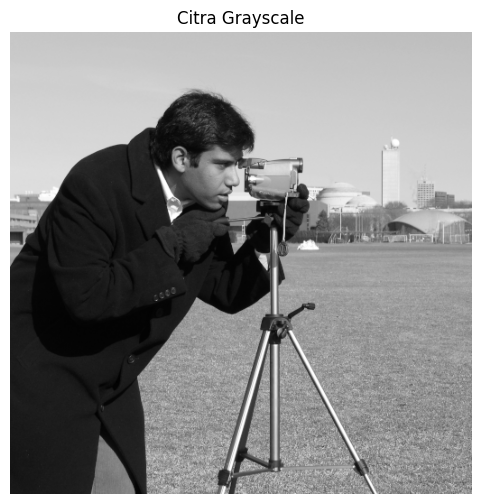

In [102]:
# @title Menampilkan Citra Camera
plt.figure(figsize=(8, 6))
plt.imshow(image, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")
plt.show()

## Praktikum 1 — Melihat Nilai Piksel

Ambil beberapa nilai piksel dari citra dari variable `image` yang telah di inisiasi sebelumnya dengan gambar ***camera***



In [103]:
# Membuat daftar koordinat piksel yang akan diperiksa
# Setiap pasangan berisi (baris, kolom) pada citra
koordinat = [(50, 50), (100, 100), (150, 150), (200, 200)]

# Melakukan perulangan untuk mengambil setiap koordinat
for r, c in koordinat:

    # Mengakses nilai piksel berdasarkan koordinat baris (r) dan kolom (c)
    # Kemudian menampilkan koordinat beserta nilai pikselnya
    print(f"Piksel [{r}, {c}] = {image[r, c]}")

Piksel [50, 50] = 207
Piksel [100, 100] = 212
Piksel [150, 150] = 36
Piksel [200, 200] = 47


Penjelasan konsep:
- `koordinat`: Menyimpan daftar posisi piksel yang ingin diperiksa.
- `for r, c in koordinat`: Mengambil setiap pasangan koordinat, dengan r sebagai indeks baris (row) dan c sebagai indeks kolom (column).
- `image[r, c]`: Mengakses nilai intensitas piksel pada posisi tersebut.
- `print()`: Menampilkan posisi dan nilai piksel ke layar.

Indeks diatas digunakan jika citra berukuran 256 × 256 piksel, seluruh koordinat di atas masih valid karena indeks dimulai dari 0.

Untuk citra grayscale, hasil image[r, c] berupa satu nilai intensitas (0–255). Sementara pada citra RGB, hasilnya berupa tiga nilai kanal warna, yaitu [R, G, B].

![link alt](https://knowthecode.io/wp-content/uploads/2016/10/cs0100-2.13pgrid.jpg)

### Pertanyaan Praktikum 1

1. Apakah nilai setiap piksel sama?
2. Apa arti nilai piksel yang mendekati `0`?
3. Apa arti nilai piksel yang mendekati `255`?



### **Jawaban Pertanyaan Praktikum 1**
#
#
#




---



# BAGIAN 2 — Operasi Piksel dan Brightness

## 2.1 Brightness
### 2.1.1 Konsep Brightness
**Brightness (kecerahan)** merupakan proses pengolahan citra yang bertujuan untuk membuat gambar menjadi lebih terang atau lebih gelap dengan mengubah nilai intensitas piksel.

Rumus sederhana:

\\[ I\_{baru}(x,y) = I\_{lama}(x,y) + B \\]

Keterangan:

- \\(I\_{baru}\\) = nilai intensitas piksel setelah perubahan.
- \\(I\_{lama}\\) = nilai intensitas piksel asli.
- \\(B\\) = nilai perubahan brightness.

Pengaruh nilai brightness:

| Nilai Brightness | Pengaruh           |
| ---------------- | ------------------ |
| +50              | Citra lebih terang |
| +30              | Citra lebih terang |
| 0                | Citra tetap        |
| -30              | Citra lebih gelap  |
| -50              | Citra lebih gelap  |

**Mengapa perlu clipping (pembatasan/pemotongan)?**

Pada citra grayscale 8-bit, nilai intensitas hanya boleh berada pada rentang 0–255.

- Jika hasil perhitungan lebih dari 255, nilainya dibatasi menjadi 255.
- Jika hasil perhitungan kurang dari 0, nilainya dibatasi menjadi 0.

Secara matematis:

$$I_{baru} = min(255,max(0,I_{lama}+B))$$





### **2.1.2 Visualisasi Perubahan Brightness**

<div style="display: flex; justify-content: center; gap: 10px;">

  <figure style="text-align: center; margin: 0; width:45%;">
    <img src="https://i.sstatic.net/MCZ7o.jpg" alt="Deskripsi 1" width="320">
    <figcaption> <b>Citra asli</b> - Brightness = 0 </figcaption>
  </figure>

  <figure style="text-align: center; margin: 0; width:40%;">
    <img src="https://miro.medium.com/v2/resize:fit:828/format:webp/0*MisK3q_-36cFvpXx" alt="Deskripsi 2" width="320">
    <figcaption><b>Citra lebih terang - </b> Brightness = +50 (ilustrasi)</figcaption>
  </figure>

</div>


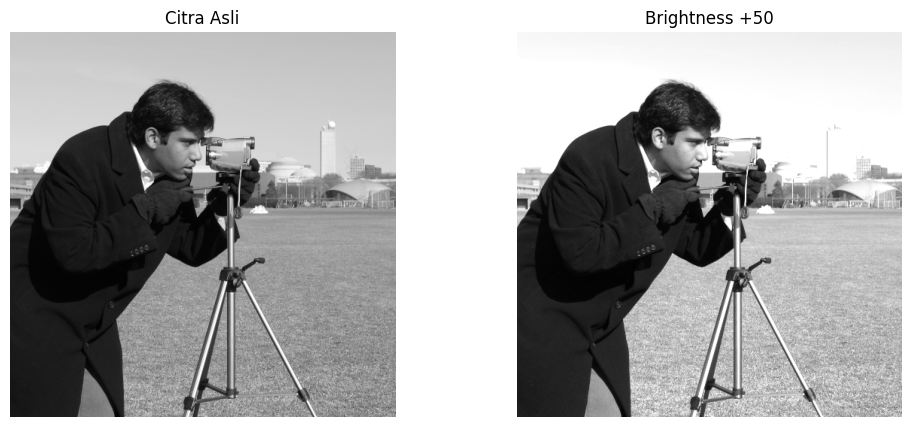

In [104]:
# @title Source Code Brightness Gambar

# Menentukan nilai perubahan kecerahan (brightness)
# Nilai positif membuat citra lebih terang,
# sedangkan nilai negatif membuat citra lebih gelap.
brightness = 50

# Mengubah tipe data citra menjadi int16 agar operasi
# penjumlahan tidak mengalami overflow pada tipe uint8.
bright_image = np.clip(
    image.astype(np.int16) + brightness,  # Menambahkan nilai brightness ke setiap piksel citra asli
    0, # Menentukan batas minimum intensitas piksel, yaitu 0 (hitam)
    255 # Menentukan batas maksimum intensitas piksel, yaitu 255 (putih)
).astype(np.uint8) # Mengubah kembali hasil pengolahan menjadi uint8 (8-bit)
                    # karena citra grayscale umumnya menggunakan rentang 0-255.

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(bright_image, cmap="gray")
plt.title(f"Brightness {brightness:+d}")
plt.axis("off")

plt.show()

### Mengapa menggunakan code `np.clip()`?

Misalnya:

```text
230 + 50 = 280
```

Padahal nilai maksimum citra 8-bit adalah `255`.

`np.clip()` akan membatasi:

```text
280 → 255
```

Begitu juga jika hasil negatif:

```text
-20 → 0
```

## Praktikum 2 — Eksperimen Brightness

1. Coba nilai berikut secara bergantian kemudian amati perubahan dari citra
   * `-50`
   * `0`
   * `20`
   * `50`
   * `100`

2. Apa yang terjadi jika nilai brightness semakin besar?
3. Apa yang terjadi jika nilai brightness negatif?
4. Mengapa kita menggunakan `np.clip()`?
5. Apa yang terjadi jika `np.clip()` tidak digunakan?

### **Jawaban Pertanyaan Praktikum 2 - Eksperimen Brightness**
#
#
#




---



# BAGIAN 3 — Contrast

## 3.1 Apa itu Contrast?

**Contrast (kontras)** menunjukkan tingkat perbedaan intensitas antara area gelap dan area terang pada sebuah citra.

Kontras menentukan seberapa jelas perbedaan antara objek dan latar belakang.

- **Kontras rendah:** Perbedaan area gelap dan terang relatif kecil sehingga gambar terlihat pucat atau kurang jelas.
- **Kontras tinggi:** Perbedaan area gelap dan terang lebih besar sehingga detail objek terlihat lebih tegas.

### **3.1.1. Ilustrasi Perbedaan Kontras**

**Kontras rendah** (Perbedaan intensitas piksel relatif kecil.)<br>
![Yuriko Noguchi (@Nogu_writer7) on X](https://pbs.twimg.com/profile_images/1876500872064270337/Pq1ZakBV.jpg)

**Kontras tinggi** Perbedaan intensitas piksel lebih tegas.
![Post in Miles Davis su © Jazzinphoto | Miles davis, Irving penn, Irving penn portrait](https://i.pinimg.com/736x/f1/73/18/f17318342deff0a9054acec754864647.jpg)



### **3.2. Perbedaan Nilai Intensitas**

Contoh sederhana:

```
Kontras rendah:
100  110  120  130  140

Kontras lebih tinggi:
20   60   120  180  240
```

Pada contoh tersebut, nilai intensitas pertama berada pada rentang yang sempit, sedangkan contoh kedua memiliki rentang nilai yang lebih lebar.

Artinya, semakin besar penyebaran nilai intensitas, semakin besar pula potensi kontras citra.

### **3.3. Rumus Perubahan Contrast**

Salah satu operasi sederhana untuk mengubah kontras adalah:

$$
I_{baru}(x,y)=I_{lama}(x,y)\times C
$$


Keterangan:

- \\(I\_{baru}\\) = nilai intensitas piksel setelah perubahan.
- \\(I\_{lama}\\) = nilai intensitas piksel asli.
- \\(C\\) = faktor pengali kontras (*contrast factor*).

Pengaruh nilai contrast:

| Faktor Kontras | Pengaruh                      |
| -------------- | ----------------------------- |
| 0.5            | Kontras cenderung menurun     |
| 0.8            | Kontras sedikit menurun       |
| 1.0            | Tidak ada perubahan           |
| 1.5            | Kontras meningkat             |
| 2.0            | Kontras meningkat lebih besar |

**Catatan**: Pengalian langsung terhadap intensitas piksel akan mengubah tingkat kecerahan sekaligus kontras. Untuk pengaturan kontras yang lebih terkontrol, biasanya digunakan nilai titik tengah (128) sebagai acuan.

Rumus alternatif:
$$
I_{baru}=128+(I_{lama}-128)\times C
$$

### **3.4. Contoh Perhitungan Manual Contrast**

Misalnya, diketahui nilai piksel:

```
50   100   128   150   200
```

Faktor kontras \\(C=1.5\\).

Contoh perhitungan:

- Piksel 50: \\(128+(50-128)\times1.5=11\\)
- Piksel 100: \\(128+(100-128)\times1.5=86\\)
- Piksel 128: \\(128+(128-128)\times1.5=128\\)
- Piksel 150: \\(128+(150-128)\times1.5=161\\)
- Piksel 200: \\(128+(200-128)\times1.5=236\\)

**Hasil perubahan:**

| Kondisi | Nilai Piksel           |
| ------- | ---------------------- |
| Sebelum | 50, 100, 128, 150, 200 |
| Sesudah | 11, 86, 128, 161, 236  |

**Kesimpulan:**

- Contrast `0.5` → kontras menurun.
- Contrast `1.0` → tidak berubah.
- Contrast `1.5` → kontras meningkat.

Semakin besar faktor kontras, semakin besar perbedaan antara area gelap dan terang.



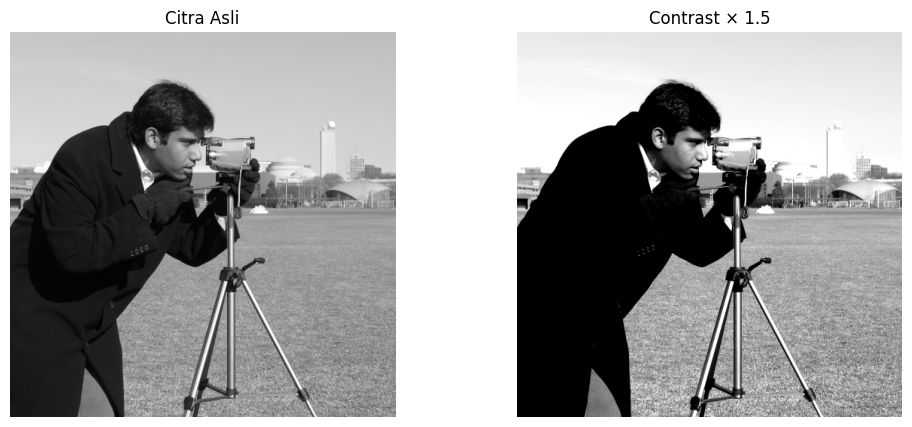

In [105]:
# Menentukan faktor kontras
contrast = 1.5

# Mengubah kontras citra berdasarkan titik tengah 128
contrast_image = np.clip(
    128 + (image.astype(np.float32) - 128) * contrast,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_image, cmap="gray")
plt.title(f"Contrast × {contrast}")
plt.axis("off")

plt.show()

##  Praktikum 3 — Eksperimen Contrast

Uji:

- `0.5`
- `1.0`
- `1.5`
- `2.0`

Amati perubahan visual.

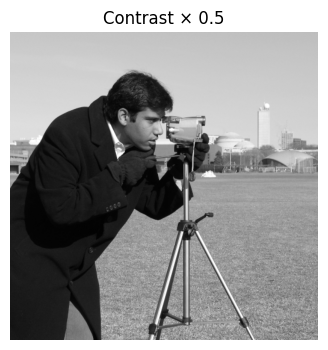

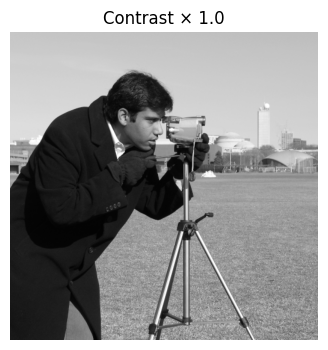

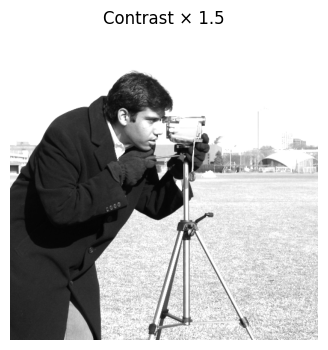

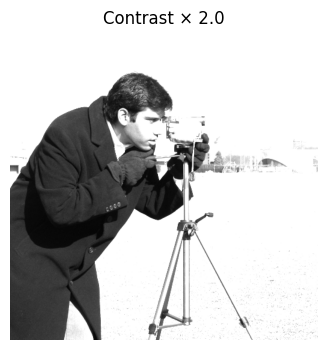

In [106]:
contrast_values = [0.5, 1.0, 1.5, 2.0]

for c in contrast_values:
    result = np.clip(
        image.astype(np.float32) * c,
        0,
        255
    ).astype(np.uint8)

    plt.figure(figsize=(4, 4))
    plt.imshow(result, cmap="gray")
    plt.title(f"Contrast × {c}")
    plt.axis("off")
    plt.show()

### Analisis Praktikum 3

1. Apa yang terjadi ketika faktor kontras `< 1`?
2. Apa yang terjadi ketika faktor kontras `> 1`?
3. Apakah faktor kontras yang lebih besar selalu menghasilkan citra yang lebih baik?
3. Apa fungsi penggunaan `np.clip()` dalam proses pengolahan kontras?
4. Mengapa titik tengah 128 digunakan sebagai acuan pada rumus alternatif?


### **Jawaban Pertanyaan Praktikum 3 - Eksperimen Contrast**
#
#
#




---



# BAGIAN 4 — Kombinasi Brightness dan Contrast

Brightness dan contrast dapat diterapkan bersama.

Secara sederhana:

```text
piksel baru = piksel lama × contrast + brightness
```

## **BAGIAN 4 — Kombinasi Brightness dan Contrast**

Brightness dan Contrast dapat diterapkan secara bersamaan untuk mengatur tingkat kecerahan sekaligus perbedaan intensitas antara area gelap dan terang pada citra.

Rumus sederhana:

$$I_{baru}=(I_{lama}\times C)+B $$

Keterangan:

- \\(I\_{baru}\\) = nilai piksel setelah pengolahan.
- \\(I\_{lama}\\) = nilai piksel asli.
- \\(C\\) = faktor contrast.
- \\(B\\) = nilai brightness.

### **Contoh Perhitungan Manual**

Diketahui:

- Nilai piksel awal = 100
- Contrast = 1.5
- Brightness = 30

Perhitungan:

\\[ I\_{baru}=(100\times1.5)+30 \\]

\\[ =150+30=180 \\]

**Hasil: 180**

Artinya, nilai intensitas piksel berubah dari 100 menjadi 180 sehingga citra menjadi lebih terang dengan peningkatan kontras.


**Kesimpulan:**

- Brightness mengatur kecerahan citra.
- Contrast mengatur perbedaan intensitas piksel.
- Kombinasi keduanya memungkinkan pengaturan tampilan citra secara bersamaan.

Catatan: `np.clip()` digunakan untuk memastikan nilai piksel tetap berada dalam rentang 0–255.

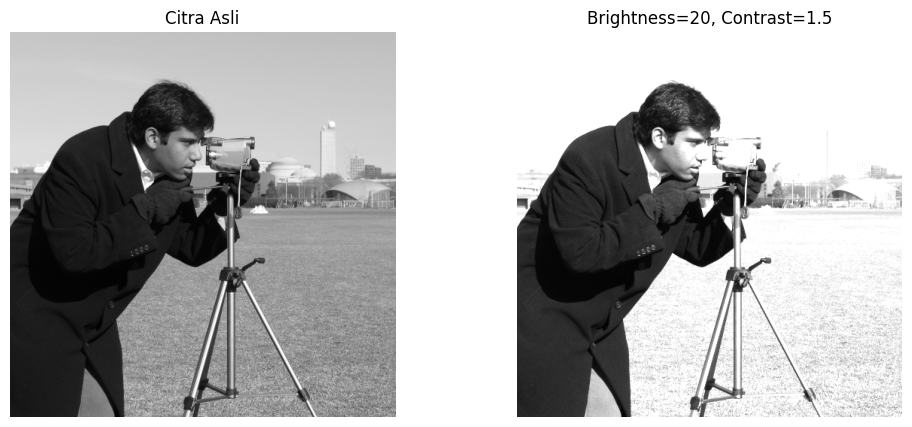

In [107]:
# Menentukan nilai contrast dan brightness
contrast = 1.5
brightness = 20

# Menggabungkan operasi contrast dan brightness
adjusted_image = np.clip(
    image.astype(np.float32) * contrast + brightness,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adjusted_image, cmap="gray")
plt.title(f"Brightness={brightness}, Contrast={contrast}")
plt.axis("off")

plt.show()

## Praktikum 4 — Mencari Kombinasi Parameter

Coba minimal 3 kombinasi berikut:

1. `brightness = -30`, `contrast = 1.5`
2. `brightness = 30`, `contrast = 2.0`
3. `brightness = 0`, `contrast = 0.5`

Kemudian tentukan kombinasi yang menurut Anda paling baik.

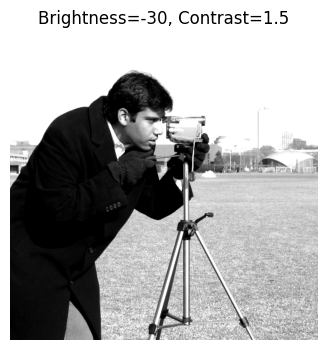

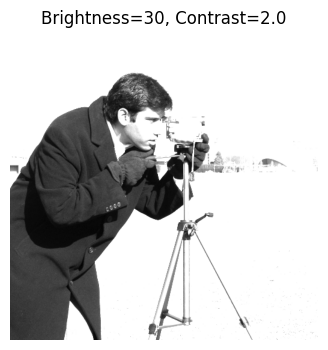

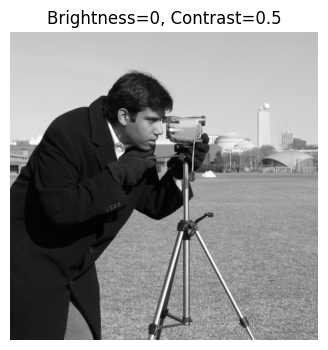

In [108]:
kombinasi = [
    (-30, 1.5),
    (30, 2.0),
    (0, 0.5)
]

for b, c in kombinasi:
    result = np.clip(
        image.astype(np.float32) * c + b,
        0,
        255
    ).astype(np.uint8)

    plt.figure(figsize=(4, 4))
    plt.imshow(result, cmap="gray")
    plt.title(f"Brightness={b}, Contrast={c}")
    plt.axis("off")
    plt.show()

###  Jawaban Praktikum 4

Kombinasi terbaik menurut saya:

**Brightness:**  
**Contrast:**  

**Alasan:**

# **BAGIAN 5 — Histogram**

## **5.1 Apa itu Histogram?**

**Histogram citra** adalah grafik yang menunjukkan distribusi jumlah piksel berdasarkan nilai intensitas pada sebuah citra.

Pada citra grayscale 8-bit, histogram memiliki rentang intensitas 0–255.

- Sumbu X (horizontal): Nilai intensitas piksel (0–255).
- Sumbu Y (vertikal): Jumlah atau frekuensi piksel pada setiap nilai intensitas.

### **5.2. Cara Membaca Histogram**

![Intensity Transformations in Digital Image Processing | by Chamuditha Kekulawala | Mar, 2026 | Medium](https://miro.medium.com/v2/resize:fit:4800/format:webp/1*kqg-bconmY1bdl7OpHI_aw.png)


- **Histogram banyak di kiri:** Citra cenderung gelap.
- **Histogram banyak di kanan:** Citra cenderung terang.
- **Histogram tersebar lebar:** Rentang intensitas lebih luas.
- **Histogram terkonsentrasi pada rentang sempit:** Salah satu indikasi kontras rendah.
  

Histogram membantu kita memahami karakteristik intensitas sebuah citra tanpa harus memeriksa nilai setiap piksel satu per satu.

Melalui histogram dapat mengetahui apakah citra cenderung gelap, terang, atau memiliki rentang kontras yang sempit maupun lebar.

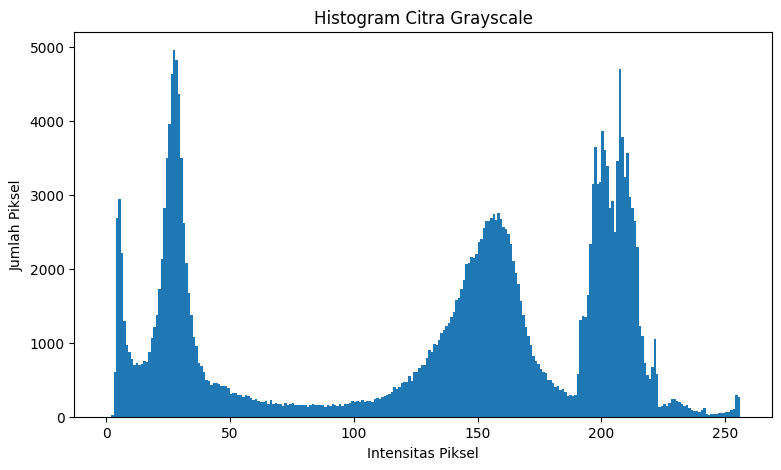

In [109]:
plt.figure(figsize=(9, 5))
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Citra Grayscale")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Jumlah Piksel")
plt.show()

**Penjelasan kode:**

| Kode             | Fungsi                                             |
| ---------------- | -------------------------------------------------- |
| `image.ravel()`  | Mengubah matriks citra menjadi array satu dimensi dari bentuk 2 dimensi (tinggixlebar). |
| `bins=256`       | Membagi histogram menjadi 256 kelompok intensitas. |
| `range=(0, 256)` | Menentukan rentang nilai intensitas.               |
| `plt.hist()`     | Membuat grafik histogram.                          |
| `plt.xlabel()`   | Memberikan label sumbu X.                          |
| `plt.ylabel()`   | Memberikan label sumbu Y.                          |

## Praktikum 5 — Citra dan Histogram

Bandingkan citra asli dengan histogramnya.

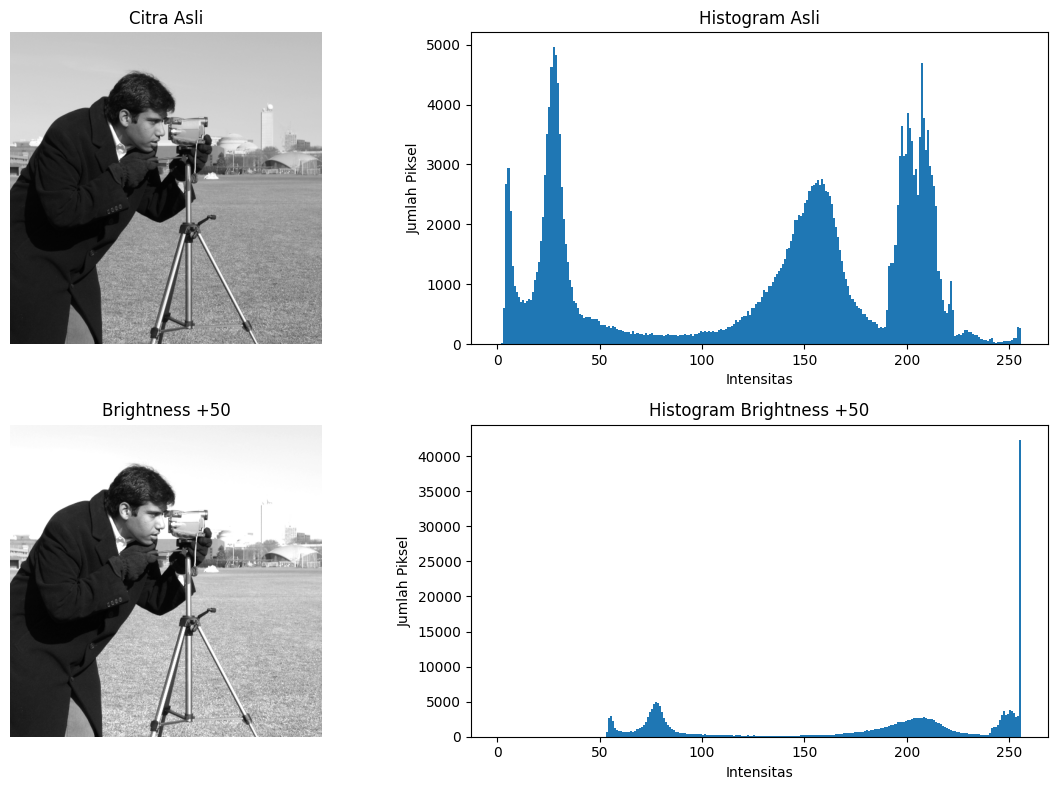

In [110]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.hist(image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Asli")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.subplot(2, 2, 3)
plt.imshow(bright_image, cmap="gray")
plt.title("Brightness +50")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.hist(bright_image.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Brightness +50")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.show()

### Analisis Praktikum 5 - Histogram

1. Apakah histogram berubah setelah brightness ditingkatkan?
2. Ke arah mana distribusi histogram cenderung bergeser?
3. Apakah perubahan histogram sesuai dengan perubahan visual citra?


###  **Jawaban Praktikum 5 - Histogram**


#Bagian 6 : Penentuan Nilai Brightness dan Contrast pada Citra Digital

Untuk menentukan nilai **Brightness** dan **Contrast**, Kita tidak harus menebak angka secara sembarangan. Nilainya dapat ditentukan dengan melihat kondisi citra dan histogramnya.

Dalam praktikum, kita bisa menggunakan pendekatan sederhana:
1. amati kondisi citra
2. periksa histogram
3. tentukan nilai awal
4. coba beberapa nilai
5. bandingkan hasilnya.

## **6.1. Menentukan nilai Brightness**

Brightness digunakan untuk mengatur tingkat kecerahan citra.

Pada citra grayscale, nilai piksel berada pada rentang 0–255:

- 0 = hitam.
- 128 = abu-abu sedang.
- 255 = putih.

Rumus:

$$I_{baru} = I_{lama} + B $$

Keterangan:

- \\(I\_{lama}\\) = nilai piksel awal.
- \\(B\\) = nilai perubahan brightness.
- \\(I\_{baru}\\) = nilai piksel setelah diubah.

**Cara menentukan nilai B:**

| Kondisi citra  | Nilai B awal | Keterangan           |
| -------------- | ------------ | -------------------- |
| Terlalu gelap  | +30          | Sedikit lebih terang |
| Sangat gelap   | +60          | Lebih terang         |
| Normal         | 0            | Tidak ada perubahan  |
| Terlalu terang | -30          | Sedikit lebih gelap  |
| Sangat terang  | -60          | Lebih gelap          |

Angka tersebut merupakan nilai percobaan awal, bukan aturan mutlak. Sesuaikan berdasarkan hasil pengamatan.

## **6.2. Menentukan nilai Contrast**

Contrast digunakan untuk mengatur perbedaan antara bagian gelap dan terang pada citra.

Rumus yang digunakan:

$$I_{baru} = 128 + (I_{lama}-128)\times C$$

Keterangan:

- \\(I\_{lama}\\) = nilai piksel awal.
- \\(128\\) = titik tengah intensitas grayscale.
- \\(C\\) = faktor contrast.
- \\(I\_{baru}\\) = nilai piksel setelah diubah.

**Cara menentukan nilai C:**

| Kondisi citra          | Nilai C awal | Keterangan                     |
| ---------------------- | ------------ | ------------------------------ |
| Kontras sangat rendah  | 1.5          | Meningkatkan kontras           |
| Kontras rendah         | 1.2          | Sedikit meningkatkan kontras   |
| Normal                 | 1.0          | Tidak ada perubahan            |
| Kontras terlalu tinggi | 0.8          | Mengurangi kontras             |
| Kontras sangat tinggi  | 0.5          | Mengurangi kontras lebih besar |

Prinsipnya:

- \\(C > 1\\): Kontras meningkat.
- \\(C = 1\\): Kontras tetap.
- \\(0 < C < 1\\): Kontras menurun.



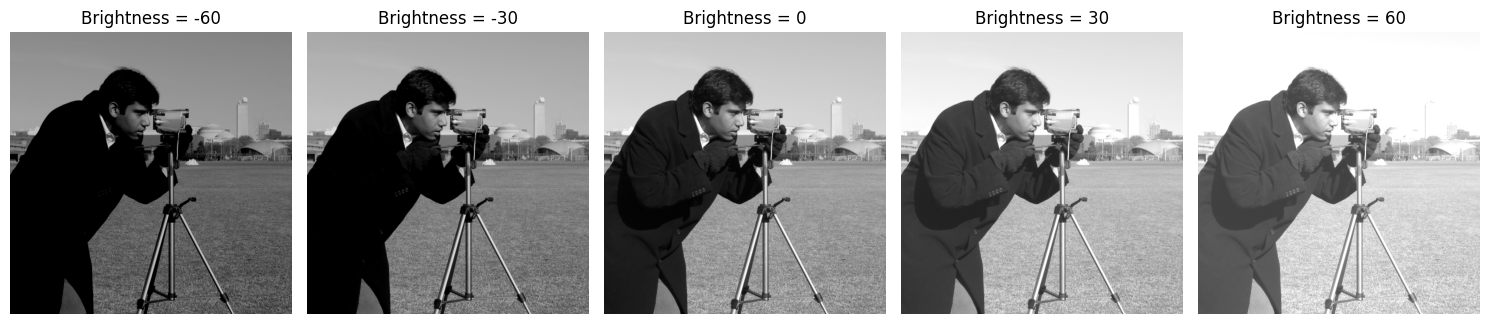

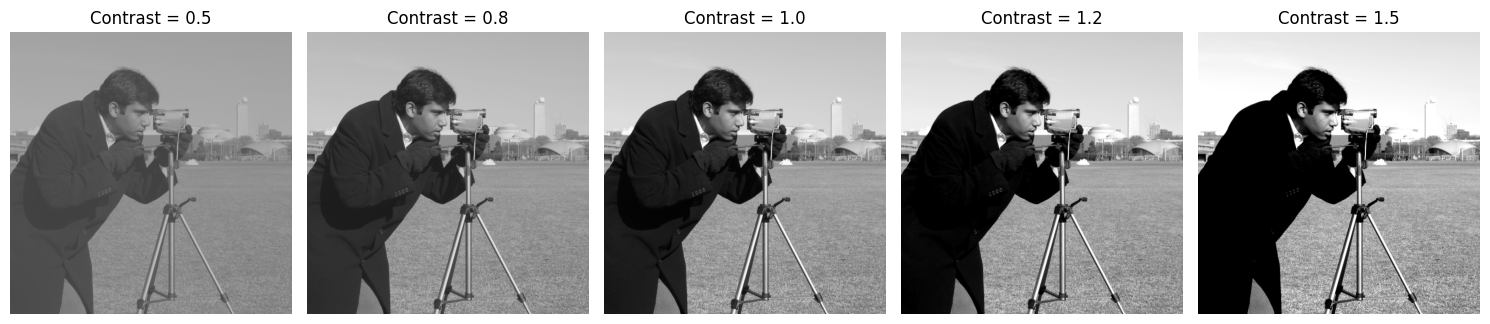

In [122]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Mengambil contoh citra grayscale
image = data.camera()

# Pengaturan nilai brightness dan contrast
brightness_values = [-60, -30, 0, 30, 60]
contrast_values = [0.5, 0.8, 1.0, 1.2, 1.5]

# Menampilkan hasil perubahan brightness
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, B in zip(axes, brightness_values):
    result = np.clip(
        image.astype(np.float32) + B, 0, 255
    ).astype(np.uint8)

    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Brightness = {B}')
    ax.axis('off')

plt.tight_layout()
plt.show()

# Menampilkan hasil perubahan contrast
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, C in zip(axes, contrast_values):
    result = 128 + (image.astype(np.float32) - 128) * C
    result = np.clip(result, 0, 255).astype(np.uint8)

    ax.imshow(result, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Contrast = {C}')
    ax.axis('off')

plt.tight_layout()
plt.show()

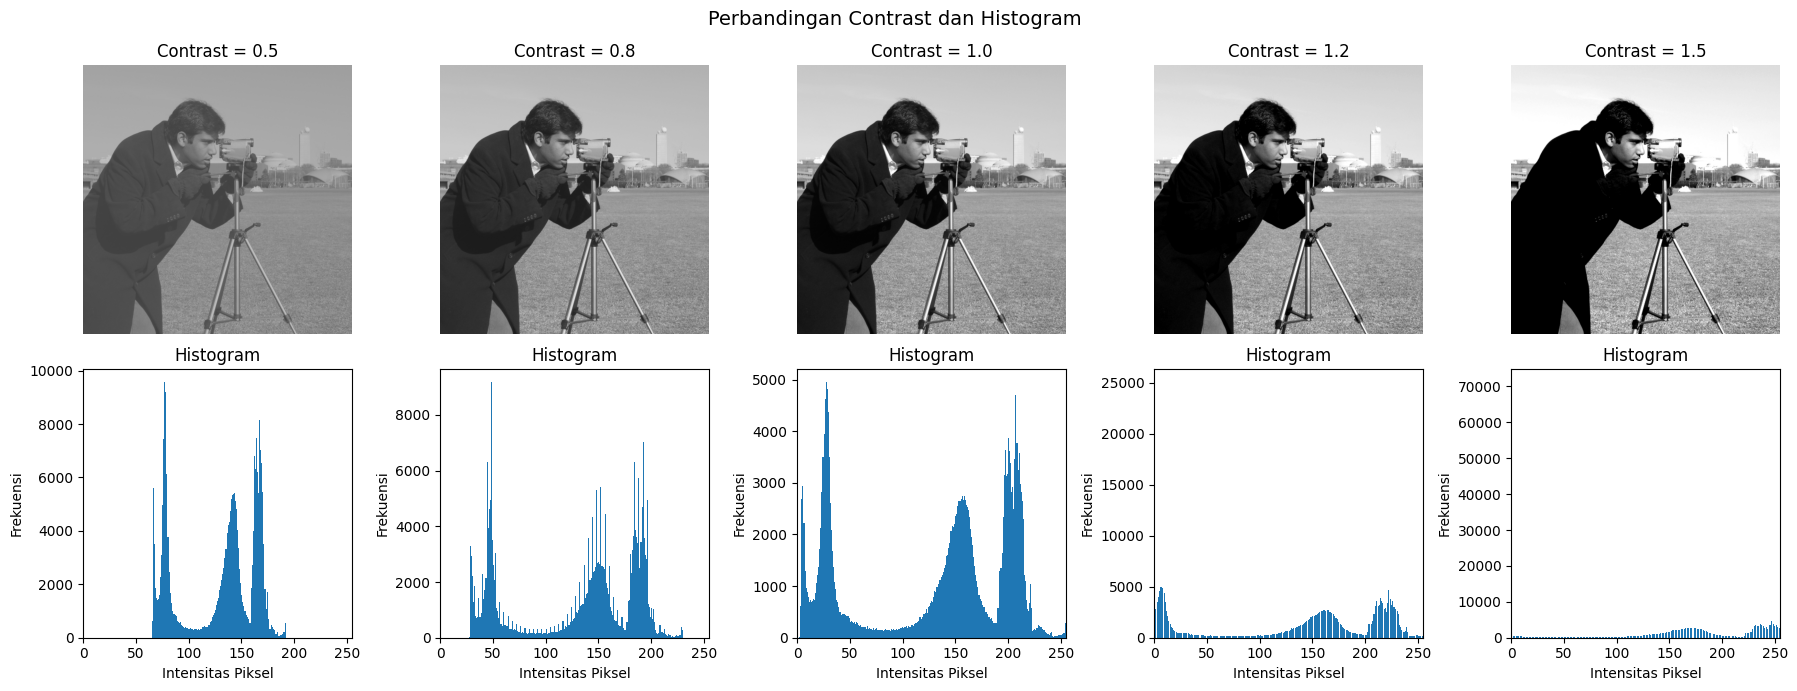

In [124]:
# @title Histogram perubahan Brightness
# Nilai contrast yang akan diuji
contrast_values = [0.5, 0.8, 1.0, 1.2, 1.5]

# Membuat area plot: 2 baris (citra dan histogram), 5 kolom
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, C in enumerate(contrast_values):

    # Mengubah contrast
    result = 128 + (image.astype(np.float32) - 128) * C
    result = np.clip(result, 0, 255).astype(np.uint8)

    # Menampilkan citra
    axes[0, i].imshow(result, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'Contrast = {C}')
    axes[0, i].axis('off')

    # Menampilkan histogram
    axes[1, i].hist(result.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title('Histogram')
    axes[1, i].set_xlabel('Intensitas Piksel')
    axes[1, i].set_ylabel('Frekuensi')
    axes[1, i].set_xlim(0, 255)

plt.suptitle('Perbandingan Contrast dan Histogram', fontsize=14)
plt.tight_layout()
plt.show()

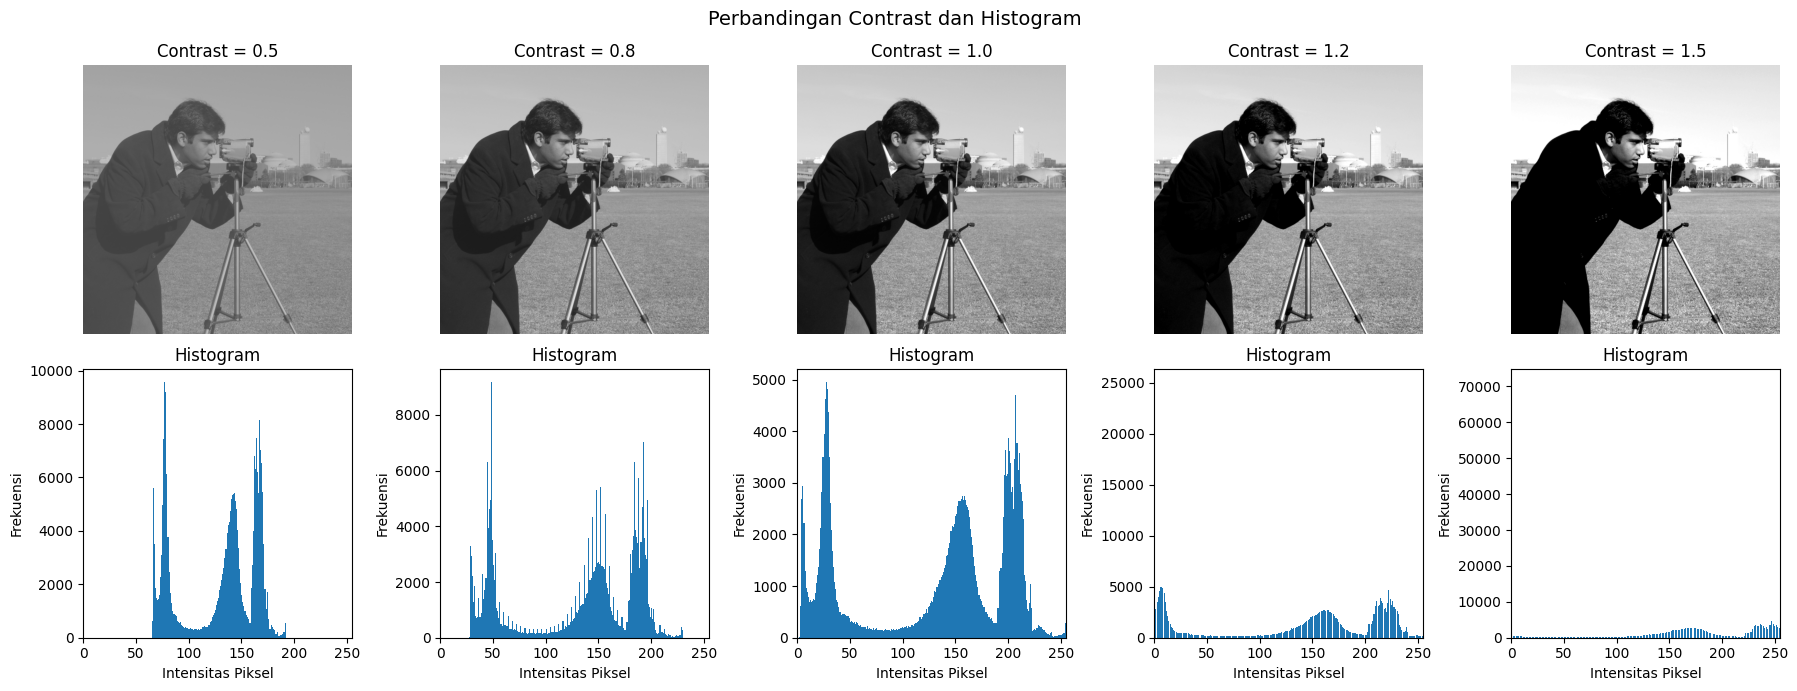

In [125]:
#@ Histogram Perubahan Contrast

# Nilai contrast yang akan diuji
contrast_values = [0.5, 0.8, 1.0, 1.2, 1.5]

# Membuat area plot: 2 baris (citra dan histogram), 5 kolom
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, C in enumerate(contrast_values):

    # Mengubah contrast
    result = 128 + (image.astype(np.float32) - 128) * C
    result = np.clip(result, 0, 255).astype(np.uint8)

    # Menampilkan citra
    axes[0, i].imshow(result, cmap='gray', vmin=0, vmax=255)
    axes[0, i].set_title(f'Contrast = {C}')
    axes[0, i].axis('off')

    # Menampilkan histogram
    axes[1, i].hist(result.ravel(), bins=256, range=(0, 256))
    axes[1, i].set_title('Histogram')
    axes[1, i].set_xlabel('Intensitas Piksel')
    axes[1, i].set_ylabel('Frekuensi')
    axes[1, i].set_xlim(0, 255)

plt.suptitle('Perbandingan Contrast dan Histogram', fontsize=14)
plt.tight_layout()
plt.show()

## **4. Menentukan nilai berdasarkan histogram**

Histogram dapat membantu Kita menentukan apakah citra perlu ditingkatkan atau diturunkan kecerahan dan kontrasnya.

<div align="center">
    <img src="https://images.openai.com/static-rsc-4/K-fn0X2tGVmil_Foj3U3iaiBUV5cwMAs8-D7WKKcZRqRI3GHrsl2JHUhRp6mKHnhtxQ8Cn57KKWlscC8tQNJWeJ6bmyk77wCL92txjP9Upjn858TkCmcou3KoniwpiAva5kfvpYlf3G44uRRf_dQipV71WNV6S1nHoRFr7CdVF8?purpose=inline" width="400">
    <p><b>Histogram dominan di sebelah kiri</b> Citra cenderung gelap. Coba brightness positif, misalnya +30 atau +60.</p>
</div>

<div align="center">
    <img src="https://images.openai.com/static-rsc-4/aw4bK9qt7ibMAD0mP1SI9fbjYC_POtnkVF_Ug9KQ69iJqNhjIAM74sgtDBGvtcahexImKUCvTGrKtAqXCx83EQRZ_FQ8sIqNX7YZXYCzbQKqUdm6kLB8N6rIc2Hy6szNz1odRv_sNa1ULhNPlIjsv55gLkguc0LWYjRlmoge8dY?purpose=inline" width="400">
    <p><b>Histogram dominan di sebelah kanan</b> Citra cenderung terang. Coba brightness negatif, misalnya -30 atau -60.</p>
</div>

 <div align="center">
    <img src="https://images.openai.com/static-rsc-4/Ermey2qBSdLfoobDHrfgI14BQ5tNVJA58O-AVqfUYZsI2TVRmEpv3SF0kYjsiOq3xskeMYu1rgMXuEIgqAryIJoc8uG6zKG0rSSpwTaPWGxEPaua9wIF8JC8BHukSam_CpKOlFRfu5kg4sHJJOYH48aKg6QlmGGKkIFHqtVMidE?purpose=inline" width="400">
    <p><b>Histogram mengumpul pada rentang sempit</b> Citra cenderung memiliki kontras rendah. Coba contrast lebih dari 1, misalnya 1.2 atau 1.5.</p>
</div>

<div align="center">
    <img src="https://images.openai.com/static-rsc-4/pOVCA3jKag43U075C2RWxp9xi2zzcP23yw_b3iS0KxkeBLWAQcqR_XDzdR-QBNjOLorDciHo4Ju99g52Tx9IFUR9oCUuiMPCICUBY1W2OcGwke4KdnCb_8gse0zbYVsOIl9HFxRBMttvkpHZ7zX280ywSLNxawVmglz0d9_xFSE?purpose=inline" width="400">
    <p><b>Histogram tersebar pada rentang yang lebar</b> Citra memiliki rentang intensitas yang luas. Periksa hasil visual sebelum menambah kontras lagi.</p>
</div>




## **5. Latihan menentukan nilai oleh mahasiswa**

Untuk praktikum, saya menyarankan mahasiswa tidak langsung diberi satu angka yang dianggap paling benar. Berikan beberapa pilihan agar mereka melakukan percobaan dan memberikan alasan.

| Kasus                     | Percobaan brightness | Percobaan contrast                    |
| ------------------------- | -------------------- | ------------------------------------- |
| Citra terlalu gelap       | +30, +60             | 1.0                                   |
| Citra terlalu terang      | -30, -60             | 0.8, 1.0                              |
| Kontras rendah            | 0                    | 1.2, 1.5                              |
| Rentang intensitas sempit | 0                    | Bandingkan dengan contrast stretching |

**Pertanyaan analisis untuk mahasiswa:**

1. Mengapa Anda memilih nilai brightness tersebut?
2. Apa perubahan yang terlihat setelah brightness diubah?
3. Apa perbedaan hasil contrast 0.5, 1.0, dan 1.5?
4. Apakah peningkatan brightness selalu membuat kualitas citra lebih baik?
5. Metode mana yang memberikan hasil paling baik untuk citra yang Anda proses?

> Tidak ada satu nilai brightness atau contrast yang cocok untuk semua citra. Nilai terbaik ditentukan berdasarkan kondisi citra, histogram, dan hasil visual setelah pemrosesan. Selain itu, nilai piksel yang terpotong menjadi 0 atau 255 dapat menyebabkan detail gambar hilang.

# Tugas Praktikum: Peningkatan Kualitas Citra Digital

## A. Instruksi Pengerjaan

Gunakan Google Colab yang terhubung dengan Github serta library Python yang telah dipelajari pada praktikum ini.

Gunakan citra grayscale dari `skimage.data.camera()` atau gambar grayscale milik sendiri.

### Tugas 1. aMengamati Citra dan Histogram
1. Tampilkan citra grayscale yang digunakan.
2. Tampilkan histogram citra tersebut.
3. Amati kondisi citra berdasarkan tampilan dan histogramnya.

### Tugas 2. Percobaan Brightness
Lakukan perubahan brightness menggunakan nilai berikut:

- -50
- 0
- +50

Tampilkan hasil setiap perubahan citra beserta histogramnya.

**Pertanyaan:** Apa yang terjadi pada citra dan histogram ketika brightness ditambah atau dikurangi?

### Tugas 3. Percobaan Contrast
Lakukan perubahan contrast menggunakan nilai berikut:

- 0.5
- 1.0
- 1.5

Tampilkan hasil setiap perubahan citra beserta histogramnya.

**Pertanyaan:** Apa perbedaan hasil citra ketika nilai contrast diperkecil dan diperbesar?

### Tugas 4. Contrast Stretching
Lakukan proses contrast stretching pada citra asli.

Tampilkan:
1. Citra sebelum contrast stretching.
2. Citra setelah contrast stretching.
3. Histogram sebelum dan sesudah contrast stretching.

**Pertanyaan:** Apa perubahan yang terlihat setelah contrast stretching dilakukan?

### Tugas 5. Kesimpulan
Buat kesimpulan singkat berdasarkan hasil percobaan. Jelaskan:
1. Perbedaan fungsi brightness dan contrast.
2. Pengaruh perubahan brightness dan contrast terhadap histogram.
3. Manfaat contrast stretching dalam meningkatkan kualitas citra.

## C. Ketentuan Pengumpulan

1. Kerjakan menggunakan Google Colab.
2. Sertakan kode program dan hasil visualisasi.
3. Berikan jawaban untuk setiap pertanyaan.
4. Tambahkan komentar atau penjelasan singkat pada bagian kode yang digunakan.
5. Simpan notebook dengan format nama file: `Tugas_NIM_NamaLengkap.ipynb`.

## D. Hasil yang Dikumpulkan

Mahasiswa mengumpulkan satu file notebook `.ipynb` yang berisi:
- Kode program.
- Hasil tampilan citra.
- Histogram setiap percobaan.
- Jawaban pertanyaan dan kesimpulan.

**Catatan:** Tidak perlu membuat program dari awal. Mahasiswa dapat menggunakan dan mengembangkan kode yang sudah diberikan pada materi praktikum.